# Variance Reduction with CUPED

An A/B test compares the mean of a metric in two groups. The metric is noisy: some users spend $0, some spend $400.
This noise makes the confidence interval wide, so small effects stay invisible or need many users.
**CUPED** (Controlled-experiment Using Pre-Experiment Data, Deng, Xu, Kohavi and Walker, Microsoft, 2013) removes
the part of the noise that a **pre-experiment covariate** predicts. A pre-experiment covariate is a user attribute
that the platform recorded before the randomization, for example the spend of the previous year.

This lesson applies CUPED to the Hillstrom e-mail test and reports the real gain, which is small on this data.
Then it shows when CUPED helps a lot, why the estimate stays unbiased, and the one mistake that breaks it.

**After this lesson you can:**

1. Compute the CUPED coefficient $\theta$, the adjusted metric and the expected variance reduction $\rho^2$.
2. Show that CUPED and an OLS regression with the centred covariate give the same estimate.
3. Use several covariates (regression adjustment) and an ML prediction as covariate (CUPAC).
4. Check with simulated experiments that CUPED keeps the estimate unbiased and the false positive rate at 5 %.
5. Convert a variance reduction into a sample size saving.
6. Explain why a post-treatment covariate biases the effect.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
Section 7 adds one synthetic metric (weekly sessions per user) and says so.
**Services:** none.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", category=FutureWarning)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
# two arms of the test: the men's e-mail (treatment) against no e-mail (control)
d = df[df.segment.isin(["Mens E-Mail", "No E-Mail"])].reset_index(drop=True)
d["treat"] = (d.segment == "Mens E-Mail").astype(int)
print(d.segment.value_counts().to_string())
print(d[["history", "recency", "visit", "spend"]].describe().round(2).loc[["mean", "std", "50%", "max"]])

segment
Mens E-Mail    21307
No E-Mail      21306
      history  recency  visit   spend
mean   241.86     5.76   0.14    1.04
std    256.57     3.51   0.35   15.00
50%    157.00     6.00   0.00    0.00
max   3345.93    12.00   1.00  499.00


## 1. The Problem: Noise Hides Effects

The effect estimate is the difference of the two means, $\hat\Delta = \bar Y_T - \bar Y_C$. Its standard error is

$$\operatorname{SE}(\hat\Delta) = \sqrt{\frac{\sigma_T^2}{n_T} + \frac{\sigma_C^2}{n_C}} .$$

The 95 % confidence interval is $\hat\Delta \pm 1.96\,\operatorname{SE}$. With a fixed number of users, the only way to
make the interval narrower is a smaller variance $\sigma^2$. The cell prints the plain estimate for two outcomes of
the e-mail test. The outcome `spend` is the dollars in the two weeks after the e-mail. The outcome `visit` is 1 if the user visited the site.

In [2]:
def diff_ci(y, t):
    # difference in means, Welch standard error and 95 % CI width
    y, t = np.asarray(y, dtype=float), np.asarray(t, dtype=bool)
    yt, yc = y[t], y[~t]
    est = yt.mean() - yc.mean()
    se = np.sqrt(yt.var(ddof=1) / len(yt) + yc.var(ddof=1) / len(yc))
    return est, se, 2 * 1.96 * se

for y in ["spend", "visit"]:
    est, se, width = diff_ci(d[y], d.treat)
    print(f"{y:5s}: effect {est:.4f} | SE {se:.4f} | 95 % CI [{est - width / 2:.4f}, {est + width / 2:.4f}] | "
          f"width {width:.4f} | SD of the metric {d[y].std():.3f}")

spend: effect 0.7698 | SE 0.1452 | 95 % CI [0.4851, 1.0545] | width 0.5694 | SD of the metric 14.996
visit: effect 0.0766 | SE 0.0034 | 95 % CI [0.0700, 0.0832] | width 0.0133 | SD of the metric 0.352


The men's e-mail raises spend by about $0.77 per user and the visit rate by about 7.7 percentage points.
The spend interval is wide: its width is about $0.57, 74 % of the effect itself. The standard deviation of spend
(about $15) is more than 10 times its mean, because only a few users buy anything.

## 2. CUPED in One Formula

Let $X$ be a covariate with values that existed before the randomization. CUPED replaces the outcome $Y$ with an adjusted outcome:

$$Y^{\text{cv}} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\operatorname{cov}(Y, X)}{\operatorname{var}(X)} .$$

$\theta$ is the slope of a least-squares line of $Y$ on $X$, and $\bar X$ is the mean of $X$ over both groups.
The variance of the adjusted outcome is

$$\operatorname{var}(Y^{\text{cv}}) = \operatorname{var}(Y)\,(1 - \rho^2),$$

where $\rho$ is the correlation of $Y$ and $X$. The **variance reduction** is $\rho^2$. A covariate with
$\rho = 0.7$ removes 49 % of the variance; a covariate with $\rho = 0.1$ removes only 1 %.
The effect estimate is the difference of the adjusted means:

$$\hat\Delta^{\text{cv}} = (\bar Y_T - \bar Y_C) - \theta\,(\bar X_T - \bar X_C) .$$

## 3. CUPED on Hillstrom

Hillstrom has three kinds of pre-experiment data. The column `history` is the dollars spent in the past year.
The column `recency` is the months since the last purchase. The flags `mens`, `womens` and `newbie` describe past purchases.

The cell computes $\rho$, $\theta$, the
variance reduction and the new interval width for each outcome and covariate. The coefficient $\theta$ uses both groups
together. Section 4 explains why this is correct.

In [3]:
def cuped(y, x, t):
    # CUPED-adjusted effect: theta from both groups together, x centred on its overall mean
    y, x = np.asarray(y, dtype=float), np.asarray(x, dtype=float)
    theta = np.cov(y, x)[0, 1] / x.var(ddof=1)
    y_cv = y - theta * (x - x.mean())
    return theta, y_cv, *diff_ci(y_cv, t)

rows = []
for y in ["spend", "visit"]:
    raw_est, raw_se, raw_w = diff_ci(d[y], d.treat)
    for x in ["history", "recency", "mens", "womens", "newbie"]:
        theta, y_cv, est, se, width = cuped(d[y], d[x], d.treat)
        rho = np.corrcoef(d[y], d[x])[0, 1]
        rows.append({"outcome": y, "covariate": x, "rho": rho, "theta": theta, "rho^2_%": 100 * rho**2,
                     "var_reduction_%": 100 * (1 - y_cv.var() / d[y].var()), "effect_raw": raw_est,
                     "effect_cuped": est, "CI_width_raw": raw_w, "CI_width_cuped": width})
single = pd.DataFrame(rows)
print(single.round(4).to_string(index=False))

outcome covariate     rho   theta  rho^2_%  var_reduction_%  effect_raw  effect_cuped  CI_width_raw  CI_width_cuped
  spend   history  0.0209  0.0012   0.0438           0.0461      0.7698        0.7674        0.5694          0.5692
  spend   recency -0.0165 -0.0705   0.0272           0.0295      0.7698        0.7715        0.5694          0.5693
  spend      mens  0.0143  0.4320   0.0205           0.0229      0.7698        0.7708        0.5694          0.5693
  spend    womens  0.0001  0.0043   0.0000           0.0023      0.7698        0.7698        0.5694          0.5694
  spend    newbie -0.0124 -0.3722   0.0154           0.0177      0.7698        0.7697        0.5694          0.5693
  visit   history  0.0667  0.0001   0.4444           0.4467      0.0766        0.0764        0.0133          0.0132
  visit   recency -0.0801 -0.0080   0.6414           0.6438      0.0766        0.0768        0.0133          0.0132
  visit      mens  0.0340  0.0240   0.1157           0.1180      0.0766 

The honest result: CUPED with one covariate helps little on this data.

- For `spend`, the best covariate is `history`, with $\rho = 0.021$. It removes 0.04 % of the variance. The
  interval width changes only from 0.5694 to 0.5692.
- For `visit`, `recency` is the best single covariate ($\rho = -0.080$, 0.64 % variance reduction).
- The `rho^2_%` column and the measured `var_reduction_%` column agree, as the formula predicts.

The reason is the metric, not the method. Spend in a two-week window is mostly zero, and one purchase of $300
dominates it. Last year's total spend predicts the chance of a purchase weakly, and it does not predict the size
of the purchase. Section 7 shows a metric where CUPED removes about half of the variance.

## 4. Why the Estimate Stays Unbiased

CUPED subtracts $\theta(\bar X_T - \bar X_C)$. The randomization makes the expected value of $\bar X_T - \bar X_C$
zero, because the e-mail cannot change a value that existed before it. So the correction changes the estimate
only by chance noise in $X$, and the expected value of $\hat\Delta^{\text{cv}}$ is the true effect. This also
explains why $\theta$ can come from both groups together: it is a fixed number that multiplies a term with mean zero.

A **balance check** tests this assumption. If a "pre-experiment" covariate differs between the groups, either the
randomization failed or the covariate is not pre-experiment.

In [4]:
for x in ["history", "recency", "mens", "womens", "newbie"]:
    xt, xc = d.loc[d.treat == 1, x], d.loc[d.treat == 0, x]
    p = stats.ttest_ind(xt, xc, equal_var=False).pvalue
    print(f"{x:8s} treatment mean {xt.mean():8.3f} | control mean {xc.mean():8.3f} | Welch p = {p:.3f}")

history  treatment mean  242.836 | control mean  240.883 | Welch p = 0.432
recency  treatment mean    5.774 | control mean    5.750 | Welch p = 0.481
mens     treatment mean    0.551 | control mean    0.553 | Welch p = 0.636
womens   treatment mean    0.551 | control mean    0.548 | Welch p = 0.433
newbie   treatment mean    0.502 | control mean    0.502 | Welch p = 0.927


All five covariates pass the balance check: the group means are close, and no p-value is below 0.05. They are valid CUPED
covariates.

## 5. CUPED Is a Regression

An OLS regression of the outcome on the treatment flag and the centred covariate gives almost the same estimate:

$$Y_i = \alpha + \Delta\,T_i + \beta\,(X_i - \bar X) + \varepsilon_i .$$

The coefficient $\hat\Delta$ equals $(\bar Y_T - \bar Y_C) - \hat\beta(\bar X_T - \bar X_C)$. This is the CUPED formula.
The only difference: OLS estimates the slope $\hat\beta$ **within** the groups, CUPED estimates $\theta$ over both
groups together. With a randomized treatment the two slopes are almost equal. The regression uses robust (HC1)
standard errors, because the variance of the outcome differs between the groups.

In [5]:
d["history_c"] = d.history - d.history.mean()
for y in ["spend", "visit"]:
    plain = smf.ols(f"{y} ~ treat", d).fit(cov_type="HC1")
    ols = smf.ols(f"{y} ~ treat + history_c", d).fit(cov_type="HC1")
    theta, _, est, se, _ = cuped(d[y], d.history, d.treat)
    print(f"{y:5s}: plain OLS {plain.params.treat:.5f} (SE {plain.bse.treat:.5f}) | "
          f"OLS + history {ols.params.treat:.5f} (SE {ols.bse.treat:.5f}) | CUPED {est:.5f} (SE {se:.5f})")
    print(f"       slope: OLS beta {ols.params.history_c:.6f} | CUPED theta {theta:.6f}")

spend: plain OLS 0.76983 (SE 0.14525) | OLS + history 0.76745 (SE 0.14514) | CUPED 0.76744 (SE 0.14522)
       slope: OLS beta 0.001217 | CUPED theta 0.001223
visit: plain OLS 0.07659 (SE 0.00339) | OLS + history 0.07641 (SE 0.00338) | CUPED 0.07641 (SE 0.00338)
       slope: OLS beta 0.000091 | CUPED theta 0.000091


The OLS estimate and the CUPED estimate agree to 4 decimals (0.76745 and 0.76744 for spend). The standard errors
agree to 3 decimals. The two slopes differ by less than 1 %. The regression form is useful in practice: it accepts many covariates, it gives a
standard error directly, and every statistics package has it.

## 6. Many Covariates and CUPAC

With several covariates, the regression estimates one slope for each covariate. This is **regression
adjustment**. The variance reduction is now the share of variance that all covariates explain together ($R^2$).
Categorical covariates such as `channel` and `zip_code` enter as dummy variables.

**CUPAC** (Control Using Predictions As Covariates, DoorDash, 2020) goes one step further. It trains an ML model that
predicts the outcome from the pre-experiment features. Then it uses the prediction as the single CUPED covariate. A
model can find non-linear patterns, for example "recent buyers with a high history spend more". The rules:

1. The model must not use the treatment flag or any post-treatment feature.
2. The prediction for a user must not use that user's own outcome. The cell uses 5-fold **cross-fitting**: a model
   that learns from 4 folds predicts the fifth fold.

The course environment contains scikit-learn, so the cell uses `HistGradientBoostingRegressor`.

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict

pre = "history + recency + mens + womens + newbie + C(channel) + C(zip_code)"
features = pd.get_dummies(d[["history", "recency", "mens", "womens", "newbie", "channel", "zip_code"]],
                          dtype=float)                       # pre-experiment features only, no treat flag
gain = []
for y in ["spend", "visit"]:
    se_raw = smf.ols(f"{y} ~ treat", d).fit(cov_type="HC1").bse.treat
    adj = smf.ols(f"{y} ~ treat + {pre}", d).fit(cov_type="HC1")
    model = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, min_samples_leaf=200, random_state=0)
    d[f"{y}_pred"] = cross_val_predict(model, features, d[y], cv=5)
    theta, y_cv, est, se, _ = cuped(d[y], d[f"{y}_pred"], d.treat)
    best = single[single.outcome == y]["var_reduction_%"].max()
    gain += [{"outcome": y, "method": "best single covariate", "effect": np.nan, "var_reduction_%": best},
             {"outcome": y, "method": "regression, 7 covariates", "effect": adj.params.treat,
              "var_reduction_%": 100 * (1 - (adj.bse.treat / se_raw) ** 2)},
             {"outcome": y, "method": "CUPAC (gradient boosting)", "effect": est,
              "var_reduction_%": 100 * (1 - (se / se_raw) ** 2)}]
    print(f"{y}: corr(outcome, cross-fitted prediction) = {np.corrcoef(d[y], d[f'{y}_pred'])[0, 1]:.3f}")
gain = pd.DataFrame(gain)
print(gain.round(4).to_string(index=False))

spend: corr(outcome, cross-fitted prediction) = 0.011


visit: corr(outcome, cross-fitted prediction) = 0.153
outcome                    method  effect  var_reduction_%
  spend     best single covariate     NaN           0.0461
  spend  regression, 7 covariates  0.7669           0.2516
  spend CUPAC (gradient boosting)  0.7697           0.0129
  visit     best single covariate     NaN           0.6438
  visit  regression, 7 covariates  0.0761           2.8828
  visit CUPAC (gradient boosting)  0.0764           2.3642


For `visit`, the 7 covariates together remove 2.9 % of the variance, and CUPAC removes 2.4 %. For
`spend`, both methods stay below 0.5 %. The cell computes the variance reduction from the squared standard errors,
$1 - \operatorname{SE}_{\text{adj}}^2 / \operatorname{SE}_{\text{raw}}^2$, so it shows the real gain for the effect
estimate. More covariates and a stronger model cannot create a correlation that the data does not contain.

## 7. When CUPED Helps a Lot: Stable Repeat Metrics

CUPED works best when the covariate is **the same metric, measured before the experiment**. Examples: sessions per
user, queries per user, minutes watched. These metrics are stable for each user: a heavy user last month is a heavy
user this month. Hillstrom has no such pre-period copy of `spend`, so the cell creates a synthetic metric.

The synthetic data: each of 21,306 users has a personal activity rate $\lambda_i \sim \text{Gamma}(1, 3)$.
Sessions in the pre-period week are $X_i \sim \text{Poisson}(\lambda_i)$. Sessions in the experiment week are
$Y_i \sim \text{Poisson}(\lambda_i)$, with a lift for the treatment group in section 8.

In [7]:
rng = np.random.default_rng(14)
n_users = int((d.treat == 0).sum())                  # same size as the real control group
lam = rng.gamma(shape=1.0, scale=3.0, size=n_users)  # personal activity rate, mean 3 sessions per week
sess_pre = rng.poisson(lam).astype(float)            # pre-period week (the covariate)
sess = rng.poisson(lam).astype(float)                # experiment week (the outcome, no effect yet)
rho_sess = np.corrcoef(sess, sess_pre)[0, 1]
print(f"synthetic sessions: mean {sess.mean():.2f} | SD {sess.std():.2f} | rho(pre, post) = {rho_sess:.3f} | "
      f"expected variance reduction rho^2 = {100 * rho_sess**2:.1f} %")

synthetic sessions: mean 2.96 | SD 3.43 | rho(pre, post) = 0.744 | expected variance reduction rho^2 = 55.4 %


The pre-period week predicts the experiment week with $\rho = 0.74$, so CUPED should remove about 55 % of the
variance. The Microsoft paper used metrics of this type, for example queries per user on Bing.

## 8. Simulation: Unbiased, 5 % False Positives, Smaller Variance

Section 4 gives the proof that CUPED has no bias. A simulation makes this visible. The cell takes a fixed set of
users and splits them at random into two halves 2,000 times. Each split is one simulated experiment:

1. **A/A case:** no effect. A valid test rejects $H_0$ in about 5 % of the splits (the **false positive rate**, FPR).
2. **A/B case:** the treatment half gets a known constant effect $\delta$. The mean of the 2,000 estimates must equal
   $\delta$ for an unbiased method.

The cell uses two populations: the real "No E-Mail" users with `spend` and `history`, and the synthetic sessions.
For `spend`, $\delta$ is $0.77, the effect from section 1. For sessions, $\delta$ is 0.05 sessions (1.7 %).
The splits use matrix products, so all 2,000 experiments run in a few seconds. Each split re-estimates $\theta$.

In [8]:
def split_experiments(y, x, delta, n_sims=2000, seed=0, batch=250):
    # n_sims random 50/50 splits of the same users; the treated half gets +delta.
    # Returns the plain and the CUPED estimate and standard error of every split.
    y, x = np.array(y, dtype=float), np.array(x, dtype=float)
    rng = np.random.default_rng(seed)
    n = len(y); n_t = n // 2; n_c = n - n_t
    xc = x - x.mean(); sxx = xc @ xc
    vecs = np.column_stack([y, y**2, xc, xc**2, y * xc])          # sums we need for each arm
    totals = vecs.sum(axis=0)
    out = []
    for b in range(0, n_sims, batch):
        k = min(batch, n_sims - b)
        A = np.zeros((k, n))
        np.put_along_axis(A, np.argsort(rng.random((k, n)), axis=1)[:, :n_t], 1.0, axis=1)
        St = A @ vecs; Sc = totals - St                            # per-arm sums, shape (k, 5)
        sy, syy, sx, sxx_t, syx = St.T
        # treated outcomes are y + delta
        St_y, St_yy, St_yx = sy + delta * n_t, syy + 2 * delta * sy + delta**2 * n_t, syx + delta * sx
        theta = (y @ xc + delta * sx) / sxx                        # pooled slope of (y + delta*T) on x
        def arm(s_y, s_yy, s_x, s_xx, s_yx, m):
            mean_raw, var_raw = s_y / m, (s_yy - s_y**2 / m) / (m - 1)
            z, zz = s_y - theta * s_x, s_yy - 2 * theta * s_yx + theta**2 * s_xx   # sums of y - theta*xc
            return mean_raw, var_raw, z / m, (zz - z**2 / m) / (m - 1)
        mt, vt, mzt, vzt = arm(St_y, St_yy, sx, sxx_t, St_yx, n_t)
        mc, vc, mzc, vzc = arm(*Sc.T, n_c)
        out.append(pd.DataFrame({"raw": mt - mc, "raw_se": np.sqrt(vt / n_t + vc / n_c),
                                 "cuped": mzt - mzc, "cuped_se": np.sqrt(vzt / n_t + vzc / n_c)}))
    return pd.concat(out, ignore_index=True)

ctrl = d[d.treat == 0]
cases = {"spend ~ history (real)": (ctrl.spend, ctrl.history, 0.77),
         "sessions ~ pre-week sessions (synthetic)": (sess, sess_pre, 0.05)}
sims, summary = {}, []
for name, (y, x, delta) in cases.items():
    for label, eff in [("A/A", 0.0), ("A/B", delta)]:
        r = split_experiments(y, x, eff, seed=1 if label == "A/A" else 2)
        sims[(name, label)] = r
        for m in ["raw", "cuped"]:
            summary.append({"case": name, "test": label, "method": m, "true_effect": eff,
                            "mean_estimate": r[m].mean(), "SD_estimate": r[m].std(),
                            "mean_SE": r[f"{m}_se"].mean(),
                            "reject_%": 100 * (np.abs(r[m] / r[f"{m}_se"]) > 1.96).mean()})
summary = pd.DataFrame(summary)
print(summary.round(4).to_string(index=False))

                                    case test method  true_effect  mean_estimate  SD_estimate  mean_SE  reject_%
                  spend ~ history (real)  A/A    raw         0.00        -0.0020       0.1570   0.1588      4.55
                  spend ~ history (real)  A/A  cuped         0.00        -0.0019       0.1570   0.1588      4.60
                  spend ~ history (real)  A/B    raw         0.77         0.7698       0.1601   0.1588    100.00
                  spend ~ history (real)  A/B  cuped         0.77         0.7698       0.1602   0.1588    100.00
sessions ~ pre-week sessions (synthetic)  A/A    raw         0.00        -0.0009       0.0465   0.0469      4.90
sessions ~ pre-week sessions (synthetic)  A/A  cuped         0.00        -0.0005       0.0309   0.0314      4.85
sessions ~ pre-week sessions (synthetic)  A/B    raw         0.05         0.0500       0.0468   0.0469     17.75
sessions ~ pre-week sessions (synthetic)  A/B  cuped         0.05         0.0497       0.0316   

How to read the table:

- **Unbiased:** in every A/B row, `mean_estimate` is close to `true_effect` for both methods.
- **Valid test:** in the A/A rows, `reject_%` is close to 5 % for both methods. CUPED does not create false positives.
- **Smaller variance:** for the synthetic sessions, the SD of the CUPED estimates is about two thirds of the plain SD.
  The power in the A/B rows rises from 18 % to 36 %. For real spend, the two SDs are equal.
- **Honest standard errors:** `mean_SE` is close to `SD_estimate`, so the formula for the standard error is correct.

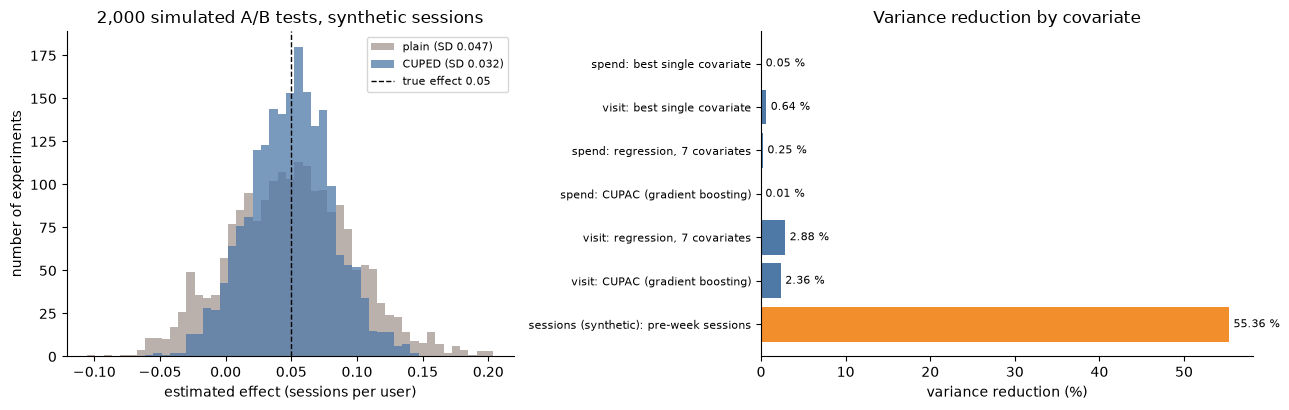

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
r = sims[("sessions ~ pre-week sessions (synthetic)", "A/B")]
bins = np.linspace(r[["raw", "cuped"]].min().min(), r[["raw", "cuped"]].max().max(), 50)
ax[0].hist(r.raw, bins=bins, color="#BAB0AC", label=f"plain (SD {r.raw.std():.3f})")
ax[0].hist(r.cuped, bins=bins, color="#4E79A7", alpha=0.75, label=f"CUPED (SD {r.cuped.std():.3f})")
ax[0].axvline(0.05, color="black", ls="--", lw=1, label="true effect 0.05")
ax[0].set(title="2,000 simulated A/B tests, synthetic sessions", xlabel="estimated effect (sessions per user)",
          ylabel="number of experiments")
ax[0].legend(fontsize=8)

bars = pd.concat([single.loc[single.groupby("outcome")["var_reduction_%"].idxmax(), ["outcome", "var_reduction_%"]]
                    .assign(method="best single covariate"),
                  gain[gain.method != "best single covariate"][["outcome", "method", "var_reduction_%"]],
                  pd.DataFrame([{"outcome": "sessions (synthetic)", "method": "pre-week sessions",
                                 "var_reduction_%": 100 * rho_sess**2}])])
labels = bars.outcome + ": " + bars.method
ax[1].barh(range(len(bars)), bars["var_reduction_%"], color=["#4E79A7"] * 6 + ["#F28E2B"])
for i, v in enumerate(bars["var_reduction_%"]):
    ax[1].text(v + 0.5, i, f"{v:.2f} %", va="center", fontsize=8)
ax[1].set_yticks(range(len(bars)), labels, fontsize=8)
ax[1].invert_yaxis()
ax[1].set(title="Variance reduction by covariate", xlabel="variance reduction (%)")
plt.tight_layout(); plt.show()

*Insight: CUPED never makes the estimate worse and never creates false positives, but its gain is exactly $\rho^2$.
On Hillstrom's two-week spend the gain is below 1 %; on a stable repeat metric with $\rho = 0.74$ it is more than half
of the variance.*

## 9. Sample Size Saving

Lesson 02 gives the sample size for each group of a two-sample test:

$$n = \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2}{\delta^2} .$$

The sample size is proportional to the variance. A variance reduction of $\rho^2$ therefore cuts the sample size
(or the run time) by the same share: $n^{\text{cv}} = n\,(1 - \rho^2)$. The cell uses $\alpha = 0.05$, a power of
80 %, the control-group variance, and the best variance reduction of each metric from sections 3, 6 and 7.

In [10]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
plan = pd.DataFrame([
    {"metric": "spend ($)", "sigma": ctrl.spend.std(), "mde": 0.25,
     "var_red": gain[gain.outcome == "spend"]["var_reduction_%"].max() / 100},
    {"metric": "visit (rate)", "sigma": ctrl.visit.std(), "mde": 0.01,
     "var_red": gain[gain.outcome == "visit"]["var_reduction_%"].max() / 100},
    {"metric": "sessions (synthetic)", "sigma": sess.std(), "mde": 0.05, "var_red": rho_sess**2}])
plan["n_per_group_plain"] = np.ceil(2 * z**2 * plan.sigma**2 / plan.mde**2).astype(int)
plan["n_per_group_cuped"] = np.ceil(plan.n_per_group_plain * (1 - plan.var_red)).astype(int)
plan["users_saved_%"] = 100 * (1 - plan.n_per_group_cuped / plan.n_per_group_plain)
print(plan.round(4).to_string(index=False))

              metric   sigma  mde  var_red  n_per_group_plain  n_per_group_cuped  users_saved_%
           spend ($) 11.5882 0.25   0.0025              33728              33644         0.2491
        visit (rate)  0.3081 0.01   0.0288              14898              14469         2.8796
sessions (synthetic)  3.4260 0.05   0.5536              73703              32904        55.3560


For `spend` with a minimum detectable effect of $0.25, CUPED saves almost nothing. For `visit` with an effect of
1 percentage point, it saves about 3 % of the users. For the synthetic sessions, the same power needs 55 % fewer
users. Thus a 4-week experiment can stop after about 2 weeks. That is the "same power with half the traffic" result that
made CUPED standard on large experimentation platforms.

## 10. The Danger: Post-Treatment Covariates

CUPED has no bias only because $X$ cannot react to the treatment. A **post-treatment covariate** gets its value
after the randomization, so the treatment can change it. Then $\bar X_T - \bar X_C$ contains part of the effect,
and the correction subtracts it. The cell uses `visit` as the covariate for `spend`. This is a mistake: the e-mail
causes visits, and visits cause spend.

In [11]:
print("balance check of visit:", d.groupby("treat").visit.mean().round(4).to_dict(),
      f"| Welch p = {stats.ttest_ind(d.visit[d.treat == 1], d.visit[d.treat == 0], equal_var=False).pvalue:.1e}")
for x in ["history", "visit"]:
    theta, y_cv, est, se, width = cuped(d.spend, d[x], d.treat)
    print(f"covariate {x:7s}: theta {theta:7.3f} | effect on spend {est:.3f} $ | 95 % CI width {width:.3f}")

balance check of visit: {0: 0.1062, 1: 0.1828} | Welch p = 1.4e-112
covariate history: theta   0.001 | effect on spend 0.767 $ | 95 % CI width 0.569
covariate visit  : theta   7.183 | effect on spend 0.220 $ | 95 % CI width 0.561


The covariate `visit` fails the balance check with a p-value far below 0.001. The "adjusted" spend effect drops from
$0.77 to about $0.22, and the interval is narrower. The narrower interval is a trap. The method now estimates the
effect of the e-mail **among users with the same visit status**. This is not the total effect. It removes the main path
of the effect (e-mail, then visit, then purchase).

Rules for a valid covariate:

1. Measure it before the first exposure of each user. Use a fixed pre-period window, for example the 4 weeks before
   the start.
2. Run the balance check of section 4 for every covariate.
3. For users without pre-period data (new users), set the covariate to a constant (for example 0) and add a flag
   "has no history". Do not drop these users.

## 11. CUPED in tea-tasting

tea-tasting 2.0 (lesson 03) supports CUPED directly: `tt.Mean(column, covariate=...)`. The covariate must be a
column of pre-experiment values. The cell compares tea-tasting with the code of this lesson.

In [12]:
import tea_tasting as tt

data = d.assign(variant=d.treat)[["variant", "spend", "visit", "history", "recency"]]
experiment = tt.Experiment(
    spend=tt.Mean("spend"),
    spend_cuped=tt.Mean("spend", covariate="history"),
    visit_cuped=tt.Mean("visit", covariate="recency"),
)
res = experiment.analyze(data)
print(res.to_pandas()[["metric", "control", "treatment", "effect_size", "effect_size_ci_lower",
                       "effect_size_ci_upper", "pvalue"]].round(5).to_string(index=False))
for y, x in [("spend", "history"), ("visit", "recency")]:
    _, _, est, se, width = cuped(d[y], d[x], d.treat)
    print(f"this lesson, {y} ~ {x}: effect {est:.5f} | CI [{est - width / 2:.5f}, {est + width / 2:.5f}]")

     metric  control  treatment  effect_size  effect_size_ci_lower  effect_size_ci_upper  pvalue
      spend  0.65279    1.42262      0.76983               0.48514               1.05451     0.0
spend_cuped  0.65398    1.42142      0.76744               0.48281               1.05206     0.0
visit_cuped  0.10607    0.18285      0.07678               0.07017               0.08340     0.0
this lesson, spend ~ history: effect 0.76744 | CI [0.48282, 1.05206]
this lesson, visit ~ recency: effect 0.07678 | CI [0.07017, 0.08340]


tea-tasting gives the same effect estimates as the lesson code to 5 decimals. The CI bounds differ by at most
0.00001. In its table, the
`control` and `treatment` columns of a CUPED metric are the adjusted means.

| situation | expected variance reduction | use CUPED? |
| :--- | :--- | :--- |
| same metric in a pre-period (sessions, queries, minutes watched) | large ($\rho^2$ often 0.3 to 0.6) | yes, always |
| sparse purchase metric, short window, weak user history | small (below 1 % here) | yes, it is free, but do not expect power |
| new users without history | none for them | yes, with a constant value and a "no history" flag |
| covariate measured after the start | not a reduction: **bias** | never |
| many covariates or non-linear patterns | $R^2$ of the model | regression adjustment or CUPAC |

## Real-World Use Case

Deng, Xu, Kohavi and Walker introduced CUPED in 2013 for the Microsoft experimentation platform (ExP) and Bing.
The paper reports that, for some metrics, pre-experiment data gives the same power with about half of the users.
The method became a default part of ExP. Booking.com described its use of CUPED in a 2018
engineering blog post. DoorDash published CUPAC in 2020, which uses an ML prediction as the covariate. Commercial and
open-source platforms such as Statsig, Eppo and GrowthBook offer CUPED as a standard option.

The practical lesson from this notebook: before a team switches CUPED on, measure $\rho$ between the metric and its
pre-period value. The expected gain is $\rho^2$, and section 9 converts it into days of run time.